<class 'numpy.ndarray'> (164, 175, 3) [0.9882353 0.9882353 0.6039216]


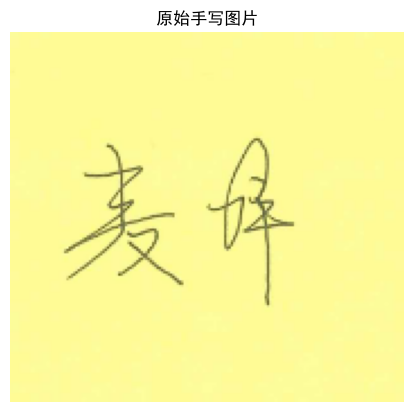

正在显示第0簇


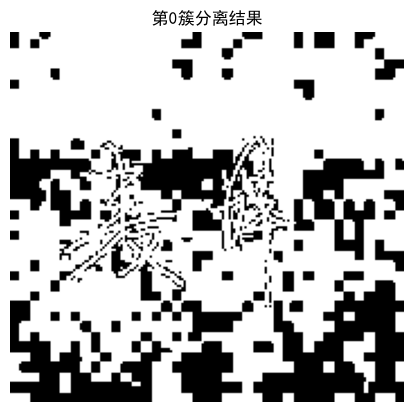

正在显示第1簇


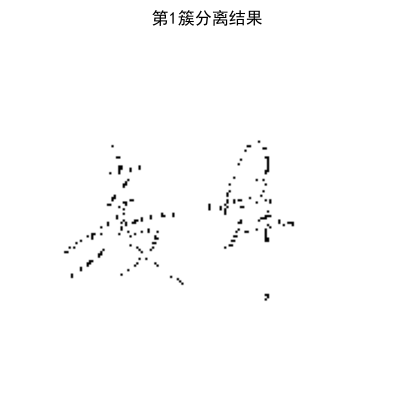

正在显示第2簇


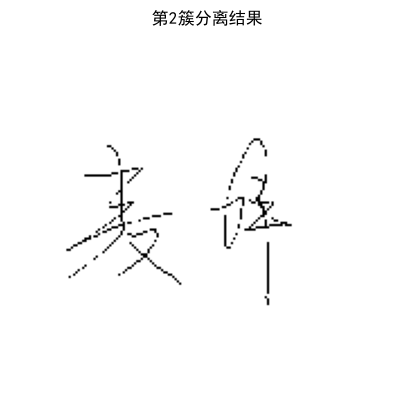

正在显示第3簇


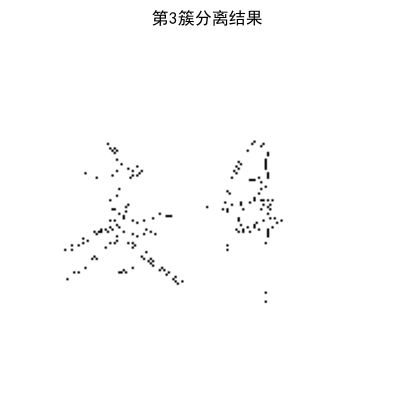

正在显示第4簇


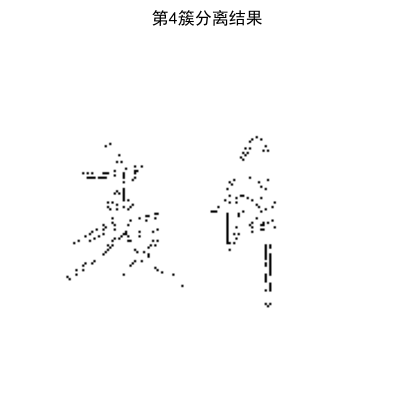

正在显示第5簇


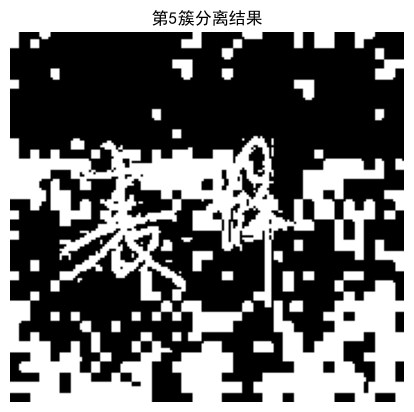

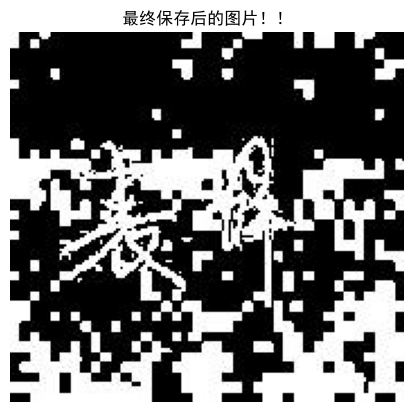

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.cluster import KMeans

# 解决中文乱
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取签名图片
path = r"mayi.png"
img = mpimg.imread(path)
print(type(img), img.shape, img[0,0])
plt.axis('off')
plt.imshow(img)
plt.title("原始手写图片")
plt.show()

# --------1：图像维度重塑，适配KMeans输入--------
height = img.shape[0]
width = img.shape[1]
# 原shape(H,W,3) → (H*W,3)，每一行代表一个像素的RGB三维特征
img1 = img.reshape((height*width, 3))

# --------2：KMeans颜色聚类，把像素分成5类--------
k = 6
kmeans = KMeans(n_clusters=k, random_state=0).fit(img1)

# --------3：取出聚类中心，转为整数方便绘图--------
center = kmeans.cluster_centers_
center = center.astype(np.int32)

# --------4：标签还原成图片二维形状，逐簇可视化--------
pic_new = np.zeros((height, width, 3), dtype='i')
label = kmeans.labels_.reshape((height, width))
n_labels = len(np.unique(kmeans.labels_))

# 循环：依次单独展示每一个簇，其余全部置白色
for k_idx in range(n_labels):
    center1 = center.copy()
    # 除当前簇以外，其他簇全部改成白色
    for i in range(n_labels):
        if i != k_idx:
            center1[i] = np.array([255, 255, 255])

    # 给每个像素分配颜色
    for i in range(height):
        for j in range(width):
            pic_new[i,j] = center1[label[i,j]]
    print(f"正在显示第{k_idx}簇")
    plt.axis('off')
    plt.imshow(pic_new)
    plt.title(f"第{k_idx}簇分离结果")
    plt.show()

# --------5：保存处理完成的去背景手写图片--------
save_name = '05-（麦译）手写图片去背景.jpg'
plt.imsave(save_name, pic_new.astype(np.uint8))

# --------6：读取刚刚保存好的图片，输出展示验证--------
img_saved = mpimg.imread(save_name)
plt.axis('off')
plt.imshow(img_saved)
plt.title("最终保存后的图片！！")
plt.show()
